In [1]:
import matplotlib.pyplot as plt
from IPython import display
import numpy as np
import time

import torch
from torch import nn
from torch.utils.data import DataLoader
import torch.nn.functional as F
from torch.linalg import norm

from common.optim.utils import get_meters, MetaData
from common.util_scripts import test_loop
from common.cnn import make_resnet18v2
from common.optim.utils import eta_calc
from common.util_optimisers import initialise_netline, initialise_lookahead, initialise_sgd

from torchvision.datasets import CIFAR100
from torchvision import transforms

import logging

In [2]:
logging.basicConfig(filename="logs/cifar100_restnet18nl.log",
                level=logging.INFO,
                format="%(levelname)s: %(asctime)s %(message)s")


#### Constants

In [3]:
BATCH_SIZE = 128
SAMPLE_SIZE = 1024
OUTPUT_DIM = 100
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

EXPERIMENTS = 1
EPOCHS_PER_EXPERIMENT = 50
DATASET_PATH = "./datasets"


#### Manual seed

In [4]:
'''
seed_value= 641

# 1. Set `PYTHONHASHSEED` environment variable at a fixed value
os.environ['PYTHONHASHSEED']=str(seed_value)
# 2. Set `python` built-in pseudo-random generator at a fixed value
random.seed(seed_value)
# 3. Set `numpy` pseudo-random generator at a fixed value
np.random.seed(seed_value)
# 4. Set `pytorch` pseudo-random generator at a fixed value
dummy=torch.manual_seed(seed_value)
'''

# The flag below controls whether to allow TF32 on matmul. This flag defaults to False in PyTorch 1.12 and later.
#torch.backends.cuda.matmul.allow_tf32 = False
#torch.backends.cuda.matmul.fp32_precision = 'ieee'

# The flag below controls whether to allow TF32 on cuDNN. This flag defaults to True.
#torch.backends.cudnn.allow_tf32 = False
#torch.backends.cudnn.conv.fp32_precision = 'tf32'


"\nseed_value= 641\n\n# 1. Set `PYTHONHASHSEED` environment variable at a fixed value\nos.environ['PYTHONHASHSEED']=str(seed_value)\n# 2. Set `python` built-in pseudo-random generator at a fixed value\nrandom.seed(seed_value)\n# 3. Set `numpy` pseudo-random generator at a fixed value\nnp.random.seed(seed_value)\n# 4. Set `pytorch` pseudo-random generator at a fixed value\ndummy=torch.manual_seed(seed_value)\n"

#### CIFAR10 dataset

In [5]:
# Data transforms (normalization & data augmentation)
stats = ((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
train_transforms = transforms.Compose([transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
                         transforms.RandomHorizontalFlip(),
                         transforms.ToTensor(),
                         transforms.Normalize(*stats,inplace=True)])
valid_transforms = transforms.Compose([transforms.ToTensor(), transforms.Normalize(*stats)])

train_dataset = CIFAR100(root=DATASET_PATH, train=True, download=True, transform=train_transforms)
test_dataset = CIFAR100(root=DATASET_PATH, train=False, download=True, transform=valid_transforms)

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
test_dataloader = DataLoader(test_dataset, batch_size=1024, num_workers=0, pin_memory=True)

d:\Programs-python\Python314\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


##### UTILS

In [6]:
def dx(xx):
    return [0]+[(next_val - current_val)/current_val for current_val, next_val in zip(xx, xx[1:])]

def experiment_comparison(data, low, high, title="Comparison"):

    MEAN_ADAM = data[low:high,0]
    MEAN_NETLINE = data[low:high,1]
    MEAN_SGD = data[low:high,2]
    cord_x = np.arange(0, len(MEAN_NETLINE[:,22]))

    #display.clear_output()
    fig, axes = plt.subplots(6, 2, figsize=(18, 36))
    axes[0,0].set_title('Loss (average cross entropy) per epoch')
    axes[0,0].plot(MEAN_ADAM[:,1], color='g',alpha=.5, label='Lookahead')
    axes[0,0].plot(MEAN_NETLINE[:,1], color='b',alpha=.5, label='Net-line')
    axes[0,0].plot(MEAN_SGD[:,1], color='grey', alpha=.5, label='SGD')
    axes[0,0].grid()
    axes[0,0].set_yscale("log")
    axes[0,0].legend()
    axes[0,0].set_xlabel("Epoch (series of gradient descent steps)")
    axes[0,0].set_ylabel("Loss value")

    axes[0,1].set_title('Error (top 1) mean per epoch')
    axes[0,1].plot(1.0-MEAN_ADAM[:,0], color='g', alpha=.5, label='Lookahead')
    axes[0,1].plot(1.0-MEAN_NETLINE[:,0], color='b', alpha=.5, label='Net-line')
    axes[0,1].plot(1.0-MEAN_SGD[:,0], color='grey', alpha=.5, label='SGD')
    axes[0,1].grid()
    axes[0,1].set_yscale("log")
    axes[0,1].legend()
    axes[0,1].set_xlabel("Epoch (series of gradient descent steps)")
    axes[0,1].set_ylabel("Error value")

    axes[1,0].set_title('PQ and PQ1 norm mean per epoch')
    axes[1,0].plot(MEAN_ADAM[:,4], color='g',alpha=.5, label='PQ norm, Lookahead')
    axes[1,0].plot(MEAN_NETLINE[:,4], color='b',alpha=.5, label='PQ norm, Net-line')
    axes[1,0].fill_between(x=cord_x, y1=MEAN_NETLINE[:,4]-MEAN_NETLINE[:,12], y2=MEAN_NETLINE[:,4]+MEAN_NETLINE[:,12], color='b', alpha=.125)
    axes[1,0].plot(MEAN_SGD[:,4], color='grey',alpha=.5, label='PQ norm, SGD')
    axes[1,0].plot(MEAN_ADAM[:,7], color='g',alpha=.5, linestyle='dashed', label='PQ1 norm, Lookahead')
    axes[1,0].plot(MEAN_NETLINE[:,7], color='b',alpha=.5, linestyle='dashed', label='PQ1 norm, Net-line')
    axes[1,0].plot(MEAN_SGD[:,7], color='grey',alpha=.5, linestyle='dashed', label='PQ1 norm, SGD')
    axes[1,0].grid()
    axes[1,0].legend()

    axes[1,1].set_title('QQ1 vector norm mean per epoch')
    axes[1,1].set_yscale("log")
    axes[1,1].plot(MEAN_NETLINE[:,3], color='orange',alpha=.5, linestyle='dashed',label='QQ1 vector norm/eta1, Net-line')
    axes[1,1].plot(MEAN_ADAM[:,10], color='g',alpha=.5, label='QQ2 vector norm/eta2, Lookahead')
    axes[1,1].plot(MEAN_NETLINE[:,10], color='b',alpha=.5, label='QQ2 vector norm/eta2, Net-line')
    axes[1,1].plot(MEAN_SGD[:,10], color='grey',alpha=.5, label='QQ2 vector norm/eta2, SGD')
    axes[1,1].grid()
    axes[1,1].legend()

    axes[2,0].set_title('Cos phi and alpha mean per epoch')
    axes[2,0].plot(MEAN_ADAM[:,5], color='g',alpha=.5, label='Cos phi, Lookahead')
    axes[2,0].plot(MEAN_NETLINE[:,5], color='b',alpha=.5, label='Cos phi, Net-line')
    axes[2,0].fill_between(x=cord_x, y1=MEAN_NETLINE[:,5]-MEAN_NETLINE[:,13], y2=MEAN_NETLINE[:,5]+MEAN_NETLINE[:,13], color='b', alpha=.125)
    axes[2,0].plot(MEAN_SGD[:,5], color='grey',alpha=.5, label='Cos phi, SGD')
    axes[2,0].plot(MEAN_NETLINE[:,15], color='magenta',alpha=.5, label='Alpha summary, Net-line')
    axes[2,0].grid()
    axes[2,0].legend()

    axes[2,1].set_title('Eta calculated')
    axes[2,1].set_yscale("log")
    axes[2,1].plot(MEAN_NETLINE[:,6], color='magenta', linestyle='dashed', alpha=.5, label='Eta2 averaged mean plus-minus one sigma per epoch')
    axes[2,1].fill_between(x=cord_x, y1=MEAN_NETLINE[:,6]-MEAN_NETLINE[:,20], y2=MEAN_NETLINE[:,6]+MEAN_NETLINE[:,20], color='magenta', alpha=.125)
    axes[2,1].plot(MEAN_NETLINE[:,21], color='blue',alpha=.5, label='Eta2 no-averaged mean plus-minus one sigma per epoch')
    axes[2,1].fill_between(x=cord_x, y1=MEAN_NETLINE[:,21]-MEAN_NETLINE[:,22], y2=MEAN_NETLINE[:,21]+MEAN_NETLINE[:,22], color='blue', alpha=.125)
    #axes[2,1].plot(MEAN_NETLINE[:,11], color='magenta', alpha=.25, label='eta_base')

    axes[2,1].plot(MEAN_NETLINE[:,19], color='green', alpha=.5, label='Eta2 averaged min per epoch')
    axes[2,1].plot(MEAN_NETLINE[:,23], color='red', alpha=.5, label='Eta2 averaged max per epoch')

    axes[2,1].plot(MEAN_SGD[:,6], color='grey', alpha=.5, label='Eta SGD mean per epoch')
    axes[2,1].grid()
    axes[2,1].legend()

    #4-PQ, 7-PQ1
    '''
    x4_nln = dx(MEAN_NETLINE[:,4])
    x4_sgd= dx(MEAN_SGD[:,4])
    x4_lah = dx(MEAN_ADAM[:,4])
    x7_nln = dx(MEAN_NETLINE[:,7])
    x7_sgd= dx(MEAN_SGD[:,7])
    x7_lah = dx(MEAN_ADAM[:,7])
    #deltas = [0]+[(next_val - current_val)/current_val for current_val, next_val in zip(x4_nl, x4_nl[1:])]

    axes[3,0].set_title('QQ1 dynamics')
    #axes[3,0].set_yscale("log")
    axes[3,0].plot(x4_lah, color='g',alpha=.5, label='Lookahead PQ average per epoch relative change')
    axes[3,0].plot(x4_nln, color='b',alpha=.5, label='Net-line PQ average per epoch relative change')
    axes[3,0].plot(x4_sgd, color='grey',alpha=.5, label='Sgd PQ average per epoch relative change')
    axes[3,0].plot(x7_lah, color='g',alpha=.5, linestyle='dashed', label='Lookahead PQ average per epoch relative change')
    axes[3,0].plot(x7_nln, color='b',alpha=.5, linestyle='dashed', label='Net-line PQ average per epoch relative change')
    axes[3,0].plot(x7_sgd, color='grey',alpha=.5, linestyle='dashed', label='Sgd PQ average per epoch relative change')
    axes[3,0].grid()
    axes[3,0].legend()
    24 - qq_min, 25 - qq_q0.25, 26 - qq_q0.5, 27 - qq_q0.75, 28 - qq_max
    '''
    axes[3,0].set_title('QQ statistics') #('Per train point projections')
    #axes[3,0].set_yscale("log")
    axes[3,0].plot(MEAN_NETLINE[:,24], color='red',alpha=.5, label='qq_min average per epoch')
    axes[3,0].plot(MEAN_NETLINE[:,25], color='tomato',alpha=.5, label='qq_q0.25 average per epoch')
    axes[3,0].plot(MEAN_NETLINE[:,26], color='slategrey',alpha=.5, label='qq_q0.5 average per epoch')
    axes[3,0].plot(MEAN_NETLINE[:,27], color='lime',alpha=.5, label='qq_q0.75 average per epoch')
    axes[3,0].plot(MEAN_NETLINE[:,28], color='green',alpha=.5, label='qq_max average per epoch')
    axes[3,0].plot(MEAN_NETLINE[:,29], color='blue',alpha=.5, label='Points part in loss average per epoch', linestyle='dashed')
    axes[3,0].plot(MEAN_NETLINE[:,35], color='magenta',alpha=.5, label='Share under average per epoch', linestyle='dashdot')
    axes[3,0].grid()
    axes[3,0].legend()

    axes[3,1].set_title('Alpha-nonmomentum and speed ratio')
    #axes[3,1].set_yscale("log")
    axes[3,1].plot(np.maximum(np.minimum(MEAN_NETLINE[:,9], 2.0), 0.0), color='green',alpha=.5, label='alpha-nonmomentum mean per epoch')
    axes[3,1].fill_between(x=cord_x, y1=MEAN_NETLINE[:,9]-MEAN_NETLINE[:,14], y2=MEAN_NETLINE[:,9]+MEAN_NETLINE[:,14], color='green', alpha=.125)
    axes[3,1].plot(MEAN_NETLINE[:,16], color='red',alpha=.5, label='speed ratio per epoch')
    axes[3,1].grid()
    axes[3,1].legend()

    axes[4,0].set_title('Passed lr ratio mean per epoch')
    #axes[4,0].set_yscale("log")
    axes[4,0].plot(MEAN_ADAM[:,8], color='g',alpha=.5, label='Lookahead')
    axes[4,0].plot(MEAN_NETLINE[:,8], color='b',alpha=.5, label='Net-line')
    axes[4,0].plot(MEAN_SGD[:,8], color='grey',alpha=.5, label='Sgd')
    axes[4,0].grid()
    axes[4,0].legend()

    axes[4,1].set_title('Cos psi mean per epoch')
    #axes[4,1].set_yscale("log")
    axes[4,1].plot(MEAN_ADAM[:,17], color='g',alpha=.5, label='Lookahead')
    axes[4,1].plot(MEAN_NETLINE[:,17], color='b',alpha=.5, label='Net-line')
    axes[4,1].plot(MEAN_SGD[:,17], color='grey',alpha=.5, label='Sgd')
    axes[4,1].grid()
    axes[4,1].legend()

    axes[5,0].set_title(f'Calculated per point eta2 quantiles mean per epoch (min={MEAN_NETLINE[-1,30]}, max={MEAN_NETLINE[-1,34]})')
    axes[5,0].plot(MEAN_NETLINE[:,31], color='tomato',alpha=.5, label='eta2pp_q0.25 average per epoch')
    axes[5,0].plot(MEAN_NETLINE[:,32], color='slategrey',alpha=.5, label='eta2pp_q0.5 average per epoch')
    axes[5,0].plot(MEAN_NETLINE[:,33], color='lime',alpha=.5, label='eta2pp_q0.75 average per epoch')
    axes[5,0].plot(MEAN_NETLINE[:,6], color='blue', linestyle='dashed', alpha=.5, label='Eta2 averaged mean per epoch')
    axes[5,0].grid()
    axes[5,0].legend()

    axes[5,1].set_title(f'PQ dot product points part depending on per point cos phi')
    axes[5,1].plot(MEAN_NETLINE[:,36], color='tomato',alpha=.5, label='Dot product part for points with cos phi in [.0;.25]')
    axes[5,1].plot(MEAN_NETLINE[:,37], color='red',alpha=.5, label='Dot product part for points with cos phi in [-.25;.0] (abs)')
    axes[5,1].plot(MEAN_NETLINE[:,38], color='blue',alpha=.5, label='Dot product part for points with cos phi < -.25 (abs)')
    axes[5,1].plot(MEAN_NETLINE[:,39], color='green',alpha=.5, label='Dot product part for points with .25 < cos phi')
    axes[5,1].grid()
    axes[5,1].set_yscale("log")
    axes[5,1].legend()
    dummy=fig.suptitle(title)
    plt.show()

def experiments_comparison(data, std, low, high, title="Comparison"):

    MEAN_ADAM = data[low:high,0]
    MEAN_NETLINE = data[low:high,1]
    MEAN_SGD = data[low:high,2]
    lowB, upB = data[low:high]-std[low:high], data[low:high]+std[low:high]
    LOW_ADAM, UP_ADAM = lowB[:,0], upB[:,0]
    LOW_NETLINE, UP_NETLINE = lowB[:,1], upB[:,1]
    LOW_SGD, UP_SGD = lowB[:,2], upB[:,2]
    cord_x = np.arange(0, len(MEAN_ADAM[:,1]))

    #display.clear_output()
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    axes[0].set_title('Loss (average cross entropy)')
    axes[0].plot(MEAN_ADAM[:,1], color='g',alpha=.5, label='Lookahead')
    if (std is not None):
        axes[0].fill_between(x=cord_x, y1=LOW_ADAM[:,1], y2=UP_ADAM[:,1], color='g', alpha=.125)
    axes[0].plot(MEAN_NETLINE[:,1], color='b',alpha=.5, label='Net-line')
    if (std is not None):
        axes[0].fill_between(x=cord_x, y1=LOW_NETLINE[:,1], y2=UP_NETLINE[:,1], color='b', alpha=.125)
    axes[0].plot(MEAN_SGD[:,1], color='grey', alpha=.5, label='SGD')
    if (std is not None):
        axes[0].fill_between(x=cord_x, y1=LOW_SGD[:,1], y2=UP_SGD[:,1], color='grey', alpha=.125)
    axes[0].grid()
    axes[0].set_yscale("log")
    axes[0].legend()
    axes[0].set_xlabel("Epoch (series of gradient descent steps)")
    axes[0].set_ylabel("Loss value")

    axes[1].set_title('Error (top 1)')
    axes[1].plot(1.0-MEAN_ADAM[:,0], color='g', alpha=.5, label='Lookahead')
    if (std is not None):
        axes[1].fill_between(x=cord_x, y1=1.0-LOW_ADAM[:,0], y2=1.0-UP_ADAM[:,0], color='g', alpha=.125)
    axes[1].plot(1.0-MEAN_NETLINE[:,0], color='b', alpha=.5, label='Net-line')
    if (std is not None):
        axes[1].fill_between(x=cord_x, y1=1.0-LOW_NETLINE[:,0], y2=1.0-UP_NETLINE[:,0], color='b', alpha=.125)
    axes[1].plot(1.0-MEAN_SGD[:,0], color='grey', alpha=.5, label='SGD')
    if (std is not None):
        axes[1].fill_between(x=cord_x, y1=1.0-LOW_SGD[:,0], y2=1.0-UP_SGD[:,0], color='grey', alpha=.125)
    axes[1].grid()
    axes[1].set_yscale("log")
    axes[1].legend()
    axes[1].set_xlabel("Epoch (series of gradient descent steps)")
    axes[1].set_ylabel("Error value")

    dummy=fig.suptitle(title)
    plt.show()

def timing_comparison(data, low, high, title="Comparison"):
    '''
    TIMING_ADAM = np.mean(data[:, low:high,0], axis=0)
    TIMING_NETLINE = np.mean(data[:, low:high,1], axis=0)
    TIMING_SGD = np.mean(data[:, low:high,2], axis=0)
    '''
    TIMING_ADAM = data[low:high,0]
    TIMING_NETLINE = data[low:high,1]
    TIMING_SGD = data[low:high,2]

    fig, axes = plt.subplots(1, 1, figsize=(12, 6))
    axes.set_title(title)
    axes.plot(TIMING_ADAM[:,2], color='g',alpha=.5, label='Lookahead')
    axes.plot(TIMING_NETLINE[:,2], color='b',alpha=.5, label='Net-line')
    axes.plot(TIMING_SGD[:,2], color='grey', alpha=.5, label='SGD')
    axes.grid()
    axes.legend()
    axes.set_xlabel("Epoch (series of gradient descent steps)")
    axes.set_ylabel("Time ns")
    plt.show()

def rf(value):
    return f"{value:.5f}"

def accuracy_comparison(exp_results, low, high, title="Validation accuracy"):
    adam_mean, adam_std = np.mean(exp_results[:, low:high, 0, 0], axis=0), np.std(exp_results[:, low:high, 0, 0], axis=0)
    nline_mean, nline_std = np.mean(exp_results[:, low:high, 1, 0], axis=0), np.std(exp_results[:, low:high, 1, 0], axis=0)
    sgd_mean, sgd_std = np.mean(exp_results[:, low:high, 2, 0], axis=0), np.std(exp_results[:, low:high, 2, 0], axis=0)

    p1, p2, p3, p4, p5 = min(10,EPOCHS_PER_EXPERIMENT), min(20,EPOCHS_PER_EXPERIMENT), min(30,EPOCHS_PER_EXPERIMENT)\
        , min(40,EPOCHS_PER_EXPERIMENT), min(100,EPOCHS_PER_EXPERIMENT)

    report = np.zeros((3,5), dtype='U256')
    for row in range(3):
        mean, std = (adam_mean, adam_std) if row == 0 else (nline_mean, nline_std) if row == 1 else (sgd_mean, sgd_std)
        for col in range(5):
            indx = p1 if col == 0 else p2 if col == 1 else p3 if col == 2 else p4 if col == 3 else p5
            report[row, col] = rf(max(mean[0:indx])) + "+/-" + rf(std[indx-1])

    fig, ax = plt.subplots(figsize=(8, 8))
    # hide axes
    #fig.patch.set_visible(False)
    ax.axis('off')
    ax.axis('tight')

    tab_plot = ax.table(cellText=report, colLabels=[str(p1)+' epochs',str(p2)+' epochs',str(p3)+' epochs',str(p4)+' epochs',str(p5)+' epochs']\
        , rowLabels=['Lookahead','Net-line','SGD'], cellLoc='left', loc='center')
    tab_plot.auto_set_font_size(False)
    tab_plot.set_fontsize(11)
    tab_plot.scale(3, 5)
    #fig.tight_layout()
    ax.set_title(title)
    plt.show()


In [7]:
SAVE_EPOCH = -30
SAVE_PREFIX = 'resnet18_cifar100_epoch30'
LOAD_PREFIX = 'resnet18_cifar100_epoch30'
DO_LOAD = False
if DO_LOAD:
    net_lookahead = make_resnet18v2(3, OUTPUT_DIM).to(DEVICE)
    net_lookahead.load_state_dict(torch.load('run_data/'+LOAD_PREFIX+'_lookahead.pth', weights_only=True)) #_lookahead.pth
    net_lookahead.eval()
    snl_net = make_resnet18v2(3, OUTPUT_DIM).to(DEVICE)
    snl_net.load_state_dict(torch.load('run_data/'+LOAD_PREFIX+'_snl.pth', weights_only=True)) #'_snl.pth'
    snl_net.eval()
    net_sgd = make_resnet18v2(3, OUTPUT_DIM).to(DEVICE)
    net_sgd.load_state_dict(torch.load('run_data/'+LOAD_PREFIX+'_sgd.pth', weights_only=True)) #'_sgd.pth'
    net_sgd.eval()
else:
    net_lookahead = make_resnet18v2(3, OUTPUT_DIM).to(DEVICE)
    snl_net = make_resnet18v2(3, OUTPUT_DIM).to(DEVICE)
    snl_net.load_state_dict(net_lookahead.state_dict())
    net_sgd = make_resnet18v2(3, OUTPUT_DIM).to(DEVICE)
    net_sgd.load_state_dict(net_lookahead.state_dict())

START_EPOCH = 0


#### Compare optimisers

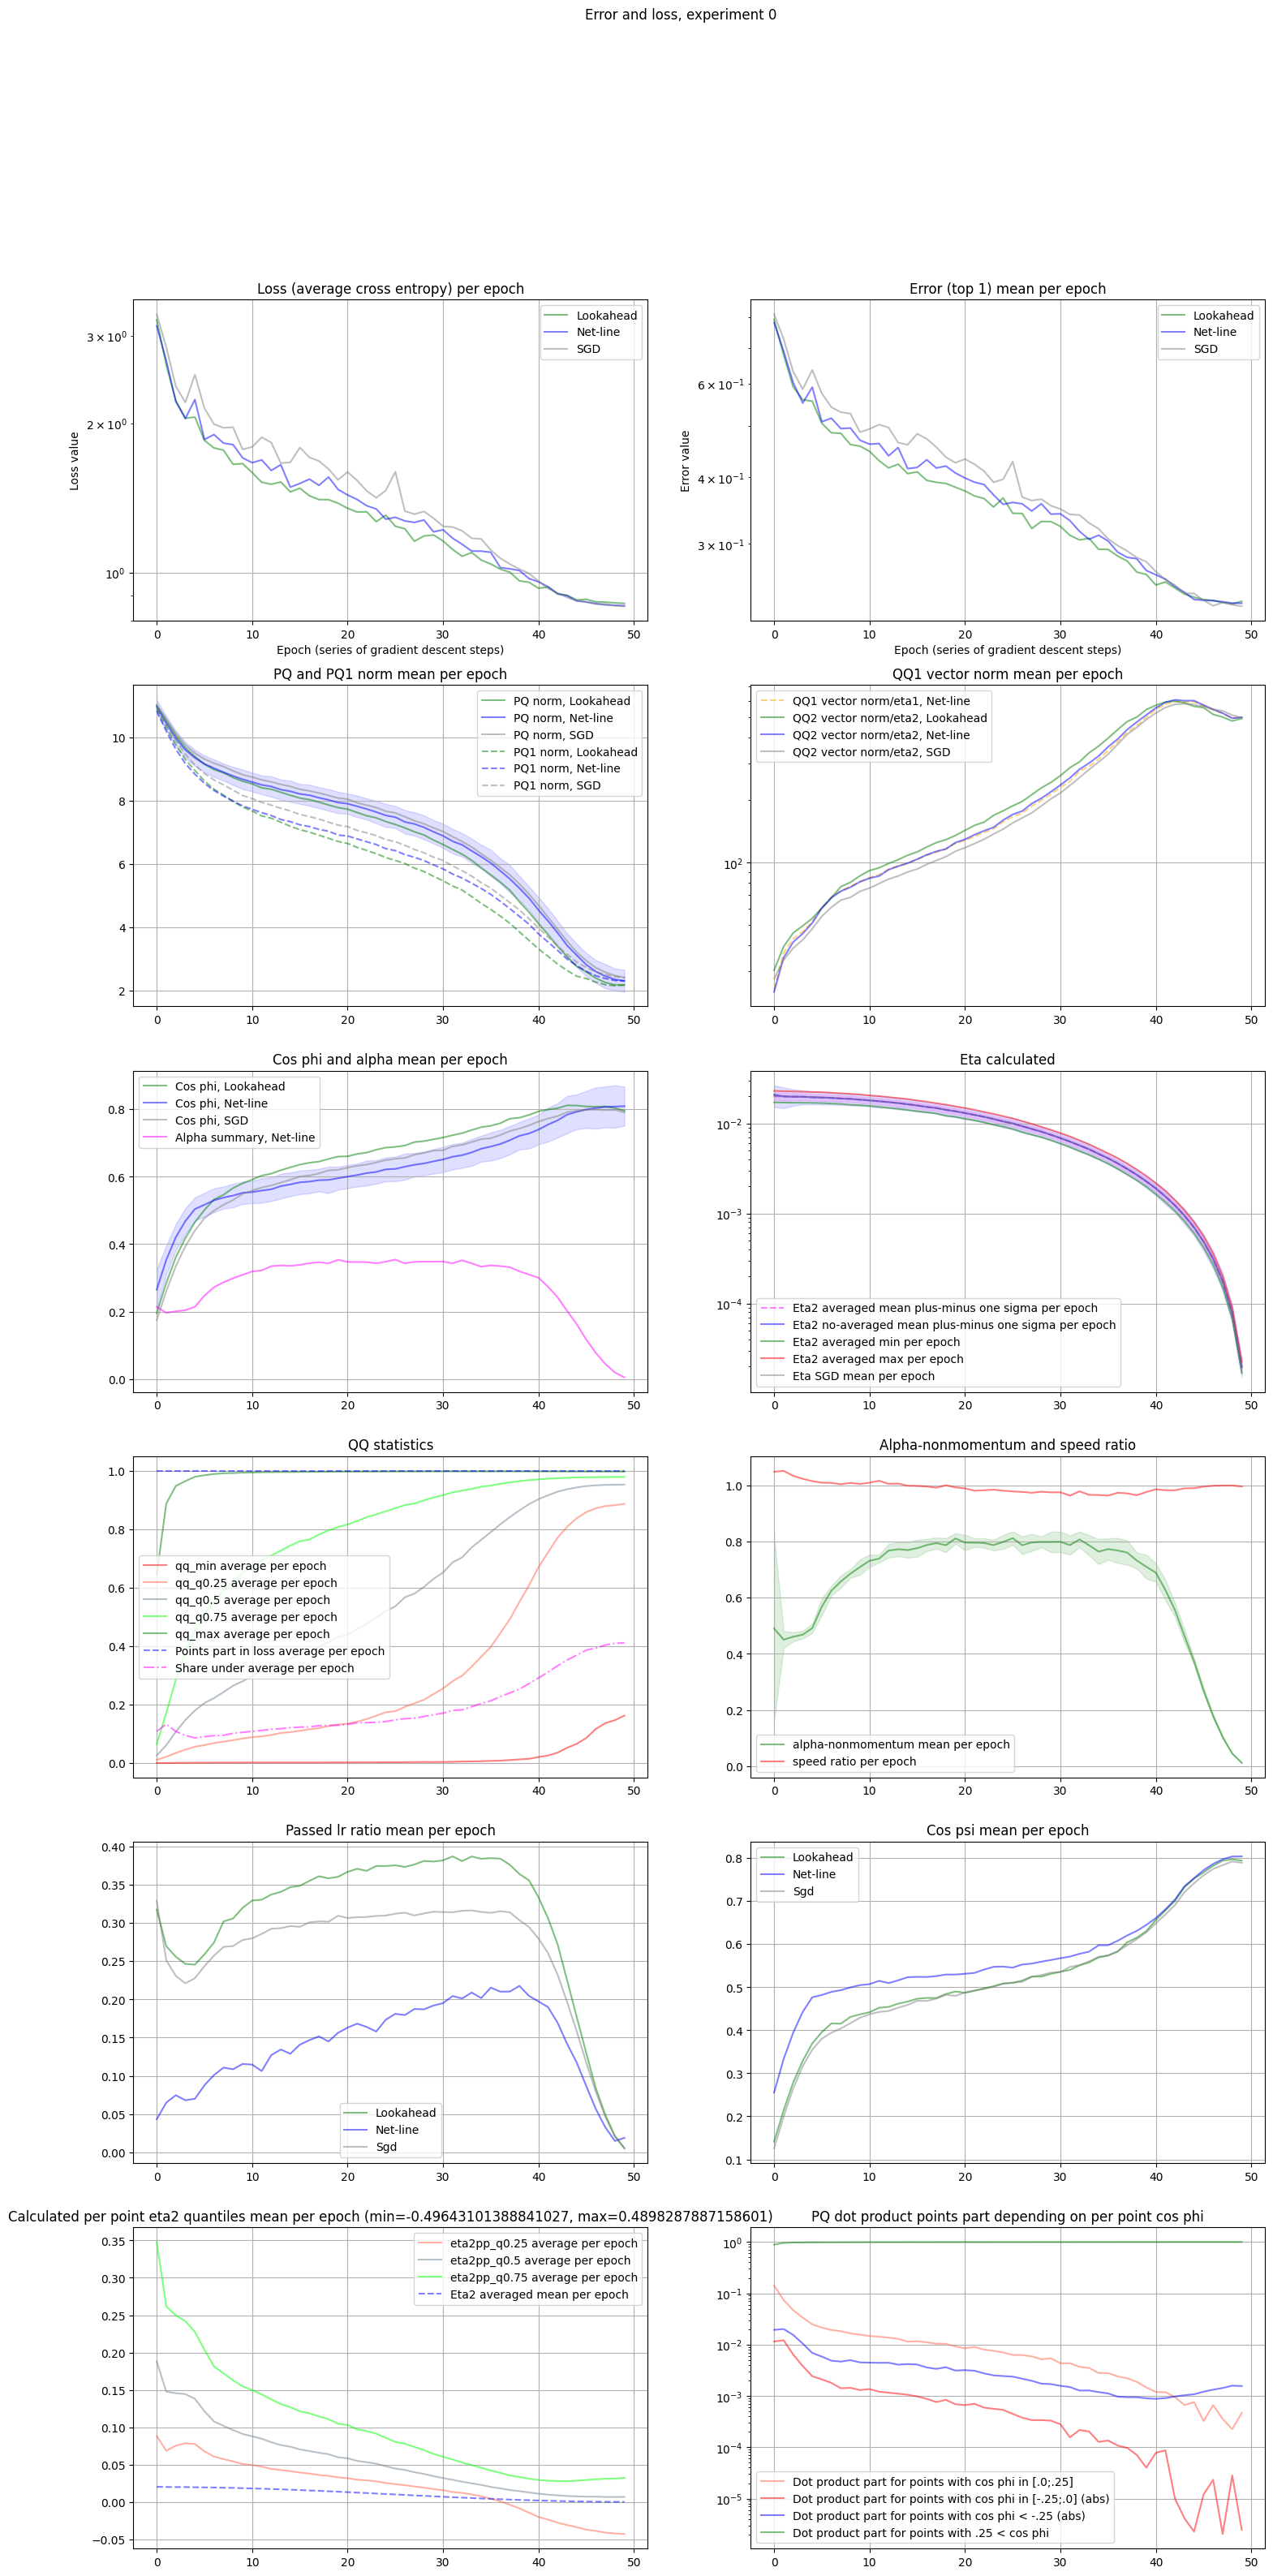

Experiment=0, epoch=49, sgd=0.7713/0.7713, net-line=0.7683/0.7683, lookahead=0.7663/0.7689, alpha_nomomentum=0.011430488899350166, cos_phi=0.8091152906417847/0.8091152906417847


In [ ]:
meta = MetaData(output_dim=OUTPUT_DIM, device=DEVICE)
beta_min = torch.tensor(1e-20).to(meta.device)

'''
0-num of experiment; 1-epoch;
2-net: 0-Lookahead, 1-Net-line 2step, 2-SGD
3-param: 0-test accuracy (Top-1), 1-test errror (cross-entropy), 2-time per step, 3 - qq_norm_test,
4 - pq_norm, 5 - cos_phi, 6 - eta2, 7 - pq1_norm, 8 - passed lr ratio, 9 - alpha_nomomentum, 10 - qq_full/eta2,
11 - lr0, 12 - pq_norm sdev, 13 - cos_phi  sdev, 14 - alpha_nomomentum sdev, 15 - alpha,
16 - speeds ratio, 17 - cos_psi, 18 - None, 19 - eta2_min, 20 - eta2_var, 21 - eta2_pre, 22 - eta2_pre_var
23 - eta2_max, 24 - qq_min, 25 - qq_q0.25, 26 - qq_q0.5, 27 - qq_q0.75, 28 - qq_qmax, 29 - points_percent
30 - eta2pp_min, 31 - eta2pp_q0.25, 32 - eta2pp_q0.5, 33 - eta2pp_q0.75, 34 - eta2pp_max,
35 - share_point_lrs_under_lr_calculated, 36 - cos_small_positive_dotprod_part, 37 - cos_small_negative_dotprod_part
38 - cos_negative_dotprod_part, 39 - cos_positive_dotprod_part
'''
experimental_results = np.zeros((EXPERIMENTS, EPOCHS_PER_EXPERIMENT, 3, 40))

lr1 = 5e-5
lr_max = 0.02
val_momentum = 0.9
val_linearity_coeff = 0.1
weight_decay = 5e-3

for experiment in range(EXPERIMENTS):

    #Lookahead
    loss_lookahead = nn.CrossEntropyLoss()
    opt_lookahead, schd_lookahead = initialise_lookahead(net_lookahead, EPOCHS_PER_EXPERIMENT, lr_max, val_momentum,\
                                                         weight_decay, la_steps=5, la_alpha=0.8)
    #Net-line dz
    snl_loss = nn.CrossEntropyLoss()
    dz_opt, dz_sch = initialise_netline(snl_net, meta, EPOCHS_PER_EXPERIMENT, lr1, lr_max, val_momentum, weight_decay,\
                                    linearity_coeff=val_linearity_coeff, la_alpha=1.0, la_steps=5)
    #Sgd scheduled lr
    loss_sgd = nn.CrossEntropyLoss()
    opt_sgd, schd_sgd = initialise_sgd(net_sgd, EPOCHS_PER_EXPERIMENT, lr_max, val_momentum, weight_decay)

    if START_EPOCH > 0:
        for _ in range(START_EPOCH):
            dz_sch.step()
            schd_sgd.step()
            schd_lookahead.step()

    for epoch in range(START_EPOCH, EPOCHS_PER_EXPERIMENT):
        if DO_LOAD == False and SAVE_EPOCH == epoch and experiment == 0:
            torch.save(net_lookahead.state_dict(), 'run_data/'+SAVE_PREFIX+'_lookahead.pth')
            torch.save(snl_net.state_dict(), 'run_data/'+SAVE_PREFIX+'_snl.pth')
            torch.save(net_sgd.state_dict(), 'run_data/'+SAVE_PREFIX+'_sgd.pth')
            
        mt_alpha, mt_lokah, mt_netline, mt_sgd, mt_qqFull, mt_non_passed, mt_alpha_nomomentum, mt_qqRatio,\
            mt_qq, mt_pq, mt_pq1, mt_phi, mt_psi, mt_eta2, mt_eta2_pre = get_meters(15)

        mt_lokah_pq, mt_lokah_pq1, mt_lokah_phi, mt_lokah_psi, mt_lokah_qqFull, mt_lokah_non_passed = get_meters(6)
        mt_sgd_pq, mt_sgd_pq1, mt_sgd_phi, mt_sgd_psi, mt_sgd_qqFull, mt_sgd_non_passed = get_meters(6)
        mt_qq_min, mt_qq_max, mt_qq_025, mt_qq_05, mt_qq_075, mt_points_percent = get_meters(6)
        mt_eta2_min, mt_eta2_025, mt_eta2_05, mt_eta2_075, mt_eta2_max, mt_share_under = get_meters(6)
        mt_cos_small_positive_dotprod_part, mt_cos_small_negative_dotprod_part,\
            mt_cos_negative_dotprod_part, mt_cos_positive_dotprod_part = get_meters(4)

        net_lookahead.train(True)
        snl_net.train(True)
        net_sgd.train(True)

        for train_batch in train_dataloader:
            images, labels = train_batch
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            pp = F.one_hot(labels, meta.output_dim)

            eta_lookahead = opt_lookahead.param_groups[0]['lr']
            logging.info("####Step with lookahead, eta={}".format(eta_lookahead))
            ns_start = time.time_ns()
            opt_lookahead.zero_grad()
            logits0 = net_lookahead.forward(images)
            with torch.no_grad():
                qq0 = F.softmax(logits0, dim=1)
            loss0 = loss_lookahead(logits0, labels)
            loss0.backward()
            opt_lookahead.step()
            torch.cuda.current_stream().synchronize()
            ns_end = time.time_ns()
            mt_lokah.update(ns_end-ns_start)

            with torch.no_grad():
                logits0_1 = net_lookahead.forward(images)
                qq0_1 = F.softmax(logits0_1, dim=1)
                delta_lookahead_pq, delta_lookahead_q1q, delta_lookahead_pq1 = pp-qq0, qq0_1-qq0, pp-qq0_1
                norm_lookahead_pq, norm_lookahead_q1q, norm_lookahead_pq1 = \
                    norm(delta_lookahead_pq, ord='fro'), norm(delta_lookahead_q1q, ord='fro'), norm(delta_lookahead_pq1, ord='fro')
                cos_lookahead_phi = torch.sum(delta_lookahead_pq*delta_lookahead_q1q)/(norm_lookahead_pq*norm_lookahead_q1q)
                cos_lookahead_psi = torch.sum(delta_lookahead_pq1*delta_lookahead_q1q)/(norm_lookahead_pq1*norm_lookahead_q1q)
                non_passed_lookahead = 1.0-torch.sqrt((1.0 - cos_lookahead_phi**2)/(1.0 - cos_lookahead_psi**2))*(cos_lookahead_psi/cos_lookahead_phi)
                
                mt_lokah_pq.update(norm_lookahead_pq)
                mt_lokah_pq1.update(norm_lookahead_pq1)
                mt_lokah_qqFull.update(norm_lookahead_q1q/eta_lookahead)
                mt_lokah_phi.update(cos_lookahead_phi)
                mt_lokah_psi.update(cos_lookahead_psi)
                mt_lokah_non_passed.update(non_passed_lookahead)

            logging.info("####Step with net-line 2step")

            ns_start = time.time_ns()
            dz_opt.zero_grad()
            dz_sch.batch_prestep()
            logitsG = snl_net.forward(images)
            lossNl, points_percent = snl_loss.forward(logitsG, labels), 1.0
            lossNl.backward()
            step_result = dz_sch.batch_step(images, labels, logitsG)
            torch.cuda.current_stream().synchronize()
            ns_end = time.time_ns()
            mt_netline.update(ns_end-ns_start)

            with torch.no_grad():
                snl_eta1_fact = dz_opt.param_groups[0]['lr1']
                qq0 = F.softmax(logitsG, dim=1)
                qq1 = step_result['qq1']
                delta_pq, delta_q1q = pp-qq0, qq1-qq0
                norm_pq, norm_qq1 = norm(delta_pq, ord='fro'), norm(delta_q1q, ord='fro')
                eta2_raw, cos_phi = eta_calc(snl_eta1_fact, delta_pq, delta_q1q, norm_pq, norm_qq1, beta_min)
                smax = torch.sum(qq0 * pp, dim = 1)
                logitsNL_1 = snl_net.forward(images)
                qqNL_1 = F.softmax(logitsNL_1, dim=1)
                delta_nl_q1q, delta_nl_pq1 = qqNL_1-qq0, pp-qqNL_1
                norm_nl_q1q, norm_nl_pq1 = norm(delta_nl_q1q, ord='fro'), norm(delta_nl_pq1, ord='fro')
                #norm_nl_qq = norm_qq1 #step_result['qq_norm'] if step_result['qq_norm'] is not None else norm_nl_q1q
                velocity_ratio_x = (norm_qq1/snl_eta1_fact)/(norm_nl_q1q/step_result['eta'])
                cos_psi = torch.sum(delta_nl_pq1*delta_nl_q1q)/(norm_nl_q1q*norm_nl_pq1)
                #cos_phi = step_result['cos_phi'] if step_result['cos_phi'] is not None else cos_psi
                non_passed_nl = 1.0-torch.sqrt((1.0 - cos_phi**2)/(1.0 - cos_psi**2))*(cos_psi/cos_phi)

                pt_pq_scalar = torch.sum(delta_pq*delta_q1q, dim=1)
                pt_pq_norm = torch.sum(delta_pq*delta_pq, dim=1) ** .5
                pt_q1q_norm = torch.sum(delta_q1q*delta_q1q, dim=1) ** .5
                eta2_per_point = snl_eta1_fact*(pt_pq_scalar/(pt_q1q_norm ** 2.0))

                eta2_quantiles = torch.quantile(eta2_per_point, torch.tensor([0.0, 0.25, 0.5, 0.75, 1.0]).to(DEVICE))
                mt_eta2_min.update(eta2_quantiles[0].item())
                mt_eta2_025.update(eta2_quantiles[1].item())
                mt_eta2_05.update(eta2_quantiles[2].item())
                mt_eta2_075.update(eta2_quantiles[3].item())
                mt_eta2_max.update(eta2_quantiles[4].item())
                mt_share_under.update(torch.sum(torch.where(eta2_per_point < step_result['eta'], 1, 0)).item()/eta2_per_point.size(0))

                pt_cos = pt_pq_scalar/(pt_pq_norm*pt_q1q_norm)
                pq_scalar = pt_pq_scalar.sum()
                pq_small_positive = pt_pq_scalar[(0.0 <= pt_cos) & (pt_cos <= 0.25)].sum()
                pq_small_negative = pt_pq_scalar[(-0.25 <= pt_cos) & (pt_cos <= 0.0)].sum().abs()
                pq_negative = pt_pq_scalar[pt_cos <= -0.25].sum().abs()
                pq_positive = pt_pq_scalar[0.25 <= pt_cos].sum()
                mt_cos_small_positive_dotprod_part.update(pq_small_positive/pq_scalar)
                mt_cos_small_negative_dotprod_part.update(pq_small_negative/pq_scalar)
                mt_cos_negative_dotprod_part.update(pq_negative/pq_scalar)
                mt_cos_positive_dotprod_part.update(pq_positive/pq_scalar)

                mt_non_passed.update(non_passed_nl)
                mt_pq.update(norm_pq)
                mt_pq1.update(norm_nl_pq1)
                mt_qq.update(norm_qq1/snl_eta1_fact)
                mt_qqFull.update(norm_nl_q1q/step_result['eta'])
                mt_qqRatio.update(velocity_ratio_x)
                mt_phi.update(cos_phi)
                mt_psi.update(cos_psi)
                mt_eta2.update(step_result['eta'])
                mt_eta2_pre.update(step_result['eta2_pre'])
                mt_alpha.update(step_result['alpha'])
                mt_alpha_nomomentum.update(step_result['alpha_nomomentum'])
                mt_points_percent.update(points_percent)

                quantiles = torch.quantile(smax, torch.tensor([0.0, 0.25, 0.5, 0.75, 1.0]).to(DEVICE))
                mt_qq_min.update(quantiles[0].item())
                mt_qq_025.update(quantiles[1].item())
                mt_qq_05.update(quantiles[2].item())
                mt_qq_075.update(quantiles[3].item())
                mt_qq_max.update(quantiles[4].item())

            eta_sgd = opt_sgd.param_groups[0]['lr']
            logging.info("####Step with SGD, eta={}".format(opt_sgd.param_groups[0]['lr']))
            ns_start = time.time_ns()
            opt_sgd.zero_grad()
            logits1 = net_sgd.forward(images)
            with torch.no_grad():
                qq1 = F.softmax(logits1, dim=1)
            loss1 = loss_sgd(logits1, labels)
            loss1.backward()
            opt_sgd.step()
            torch.cuda.current_stream().synchronize()
            ns_end = time.time_ns()
            mt_sgd.update(ns_end-ns_start)

            with torch.no_grad():
                logits1_1 = net_sgd.forward(images)
                qq1_1 = F.softmax(logits1_1, dim=1)
                delta_sgd_pq, delta_sgd_q1q, delta_sgd_pq1 = pp-qq1, qq1_1-qq1, pp - qq1_1
                norm_sgd_pq, norm_sgd_q1q, norm_sgd_pq1 = \
                    norm(delta_sgd_pq, ord='fro'), norm(delta_sgd_q1q, ord='fro'), norm(delta_sgd_pq1, ord='fro')
                cos_sgd_phi = torch.sum(delta_sgd_pq*delta_sgd_q1q)/(norm_sgd_pq*norm_sgd_q1q)
                cos_sgd_psi = torch.sum(delta_sgd_pq1*delta_sgd_q1q)/(norm_sgd_pq1*norm_sgd_q1q)
                non_passed_sgd = 1.0-torch.sqrt((1.0 - cos_sgd_phi**2)/(1.0 - cos_sgd_psi**2))*(cos_sgd_psi/cos_sgd_phi)

                mt_sgd_pq.update(norm_sgd_pq)
                mt_sgd_pq1.update(norm_sgd_pq1)
                mt_sgd_qqFull.update(norm_sgd_q1q/eta_sgd)
                mt_sgd_phi.update(cos_sgd_phi)
                mt_sgd_psi.update(cos_sgd_psi)
                mt_sgd_non_passed.update(non_passed_sgd)

        #look-ahead: qq_norm, pq_norm, cos_phi
        experimental_results[experiment, epoch, 0, 4] = mt_lokah_pq.avg()
        experimental_results[experiment, epoch, 0, 5] = mt_lokah_phi.avg()
        experimental_results[experiment, epoch, 0, 7] = mt_lokah_pq1.avg()
        experimental_results[experiment, epoch, 0, 8] = mt_lokah_non_passed.avg()
        experimental_results[experiment, epoch, 0, 17] = mt_lokah_psi.avg()
        experimental_results[experiment, epoch, 0, 10] = mt_lokah_qqFull.avg()

        #net-line: qq_norm, pq_norm, cos_phi
        experimental_results[experiment, epoch, 1, 3] = mt_qq.avg()
        experimental_results[experiment, epoch, 1, 4] = mt_pq.avg()
        experimental_results[experiment, epoch, 1, 5] = mt_phi.avg()
        experimental_results[experiment, epoch, 1, 6] = mt_eta2.avg()
        experimental_results[experiment, epoch, 1, 20] = mt_eta2.sdev_biased()
        experimental_results[experiment, epoch, 1, 21] = mt_eta2_pre.avg()
        experimental_results[experiment, epoch, 1, 22] = mt_eta2_pre.sdev_biased()
        experimental_results[experiment, epoch, 1, 11] = dz_sch.eta_target
        experimental_results[experiment, epoch, 1, 12] = mt_pq.sdev_biased()
        experimental_results[experiment, epoch, 1, 13] = mt_phi.sdev_biased()
        experimental_results[experiment, epoch, 1, 14] = mt_alpha_nomomentum.sdev_biased()
        experimental_results[experiment, epoch, 1, 15] = mt_alpha.avg()

        experimental_results[experiment, epoch, 1, 7] = mt_pq1.avg()
        experimental_results[experiment, epoch, 1, 8] = mt_non_passed.avg()
        experimental_results[experiment, epoch, 1, 9] = mt_alpha_nomomentum.avg()
        experimental_results[experiment, epoch, 1, 10] = mt_qqFull.avg()
        velocity_ratio = mt_qqRatio.avg()
        experimental_results[experiment, epoch, 1, 16] = velocity_ratio
        experimental_results[experiment, epoch, 1, 17] = mt_psi.avg()
        experimental_results[experiment, epoch, 1, 18] = 0
        experimental_results[experiment, epoch, 1, 19] = mt_eta2.min()
        experimental_results[experiment, epoch, 1, 23] = mt_eta2.max()

        experimental_results[experiment, epoch, 1, 24] = mt_qq_min.avg()
        experimental_results[experiment, epoch, 1, 25] = mt_qq_025.avg()
        experimental_results[experiment, epoch, 1, 26] = mt_qq_05.avg()
        experimental_results[experiment, epoch, 1, 27] = mt_qq_075.avg()
        experimental_results[experiment, epoch, 1, 28] = mt_qq_max.avg()
        experimental_results[experiment, epoch, 1, 29] = mt_points_percent.avg()

        experimental_results[experiment, epoch, 1, 30] = mt_eta2_min.avg()
        experimental_results[experiment, epoch, 1, 31] = mt_eta2_025.avg()
        experimental_results[experiment, epoch, 1, 32] = mt_eta2_05.avg()
        experimental_results[experiment, epoch, 1, 33] = mt_eta2_075.avg()
        experimental_results[experiment, epoch, 1, 34] = mt_eta2_max.avg()
        experimental_results[experiment, epoch, 1, 35] = mt_share_under.avg()

        experimental_results[experiment, epoch, 1, 36] = max(mt_cos_small_positive_dotprod_part.avg(), 1e-8)
        experimental_results[experiment, epoch, 1, 37] = max(mt_cos_small_negative_dotprod_part.avg(), 1e-8)
        experimental_results[experiment, epoch, 1, 38] = max(mt_cos_negative_dotprod_part.avg(), 1e-8)
        experimental_results[experiment, epoch, 1, 39] = max(mt_cos_positive_dotprod_part.avg(), 1e-8)

        #sgd: qq_norm, pq_norm, cos_phi
        experimental_results[experiment, epoch, 2, 4] = mt_sgd_pq.avg()
        experimental_results[experiment, epoch, 2, 5] = mt_sgd_phi.avg()
        experimental_results[experiment, epoch, 2, 7] = mt_sgd_pq1.avg()
        experimental_results[experiment, epoch, 2, 8] = mt_sgd_non_passed.avg()
        experimental_results[experiment, epoch, 2, 17] = mt_sgd_psi.avg()
        experimental_results[experiment, epoch, 2, 10] = mt_sgd_qqFull.avg()

        #timing
        experimental_results[experiment, epoch, 0, 2] = mt_lokah.avg()
        experimental_results[experiment, epoch, 1, 2] = mt_netline.avg()
        experimental_results[experiment, epoch, 2, 2] = mt_sgd.avg()

        # testing loop 0-Lookahead, 1-Net-line 2step, 2-SGD
        opt_lookahead._backup_and_load_cache()
        acc0, loss0 = test_loop(net_lookahead, test_dataloader, DEVICE)
        opt_lookahead._clear_and_load_backup()
        experimental_results[experiment, epoch, 0, 0] = acc0
        experimental_results[experiment, epoch, 0, 1] = loss0

        if dz_opt.la_alpha < 1.0:
            dz_opt._backup_and_load_cache()
        acc1, loss1 = test_loop(snl_net, test_dataloader, DEVICE)
        if dz_opt.la_alpha < 1.0:
            dz_opt._clear_and_load_backup()
        experimental_results[experiment, epoch, 1, 0] = acc1
        experimental_results[experiment, epoch, 1, 1] = loss1

        acc2, loss2 = test_loop(net_sgd, test_dataloader, DEVICE)
        experimental_results[experiment, epoch, 2, 0] = acc2
        experimental_results[experiment, epoch, 2, 1] = loss2
        experimental_results[experiment, epoch, 2, 6] = schd_sgd.get_last_lr()[0]
        experimental_results[experiment, epoch, 2, 11] = 0
        experimental_results[experiment, epoch, 2, 12] = 0

        snl_epoch = dz_sch._epoch
        dz_sch.step()
        schd_sgd.step()
        schd_lookahead.step()

        display.clear_output()
        title="Error and loss, experiment {}".format(experiment)
        experiment_comparison(experimental_results[experiment, START_EPOCH:epoch+1], 0, 100, title=title)

        for exp in range(experiment):
            print("Experiment={}, sgd={}, net-line={}, lookahead={}, cos_phi={}"\
                .format(exp, max(experimental_results[exp,  START_EPOCH:EPOCHS_PER_EXPERIMENT, 2, 0])\
                        , max(experimental_results[exp,  START_EPOCH:EPOCHS_PER_EXPERIMENT, 1, 0])\
                        , max(experimental_results[exp,  START_EPOCH:EPOCHS_PER_EXPERIMENT, 0, 0])\
                        , max(experimental_results[exp,  START_EPOCH:EPOCHS_PER_EXPERIMENT, 1, 5])))

        print("Experiment={}, epoch={}, sgd={}/{}, net-line={}/{}, lookahead={}/{}, alpha_nomomentum={}, cos_phi={}/{}"\
            .format(experiment, snl_epoch, acc2, max(experimental_results[experiment, START_EPOCH:epoch+1, 2, 0]), \
                    acc1, max(experimental_results[experiment, START_EPOCH:epoch+1, 1, 0]), \
                    acc0, max(experimental_results[experiment, START_EPOCH:epoch+1, 0, 0]) , mt_alpha_nomomentum.avg(), \
                    mt_phi.avg(), max(experimental_results[experiment, START_EPOCH:epoch+1, 1, 5])))



In [9]:
print("Accuracy in the latest experiment, net-line: \n{}".format(experimental_results[experiment, :, 1, 0]))

Accuracy in the latest experiment, net-line: 
[0.2195 0.3101 0.3978 0.4488 0.4097 0.4917 0.4838 0.5065 0.5054 0.5308
 0.5387 0.5375 0.5614 0.5454 0.585  0.5829 0.5688 0.584  0.5804 0.5928
 0.6015 0.6087 0.6127 0.6298 0.6445 0.6415 0.6437 0.6547 0.6435 0.6592
 0.6587 0.6687 0.6837 0.6943 0.6889 0.6967 0.7109 0.7173 0.7191 0.733
 0.7379 0.7428 0.7508 0.757  0.7645 0.7652 0.7657 0.7668 0.7681 0.7683]


In [10]:
print("Accuracy in the latest experiment, SGD: \n{}".format(experimental_results[experiment, :, 2, 0]))

Accuracy in the latest experiment, SGD: 
[0.1905 0.2724 0.3686 0.4148 0.3641 0.4251 0.4587 0.4702 0.4734 0.5142
 0.5072 0.498  0.5043 0.5357 0.5398 0.5174 0.5281 0.5445 0.564  0.5743
 0.5675 0.5771 0.5897 0.6088 0.6036 0.5722 0.6331 0.6386 0.6364 0.6465
 0.6516 0.6596 0.6605 0.6719 0.6802 0.6938 0.7025 0.7094 0.7177 0.7226
 0.7342 0.7434 0.7494 0.7581 0.7582 0.7654 0.7708 0.7675 0.7698 0.7713]


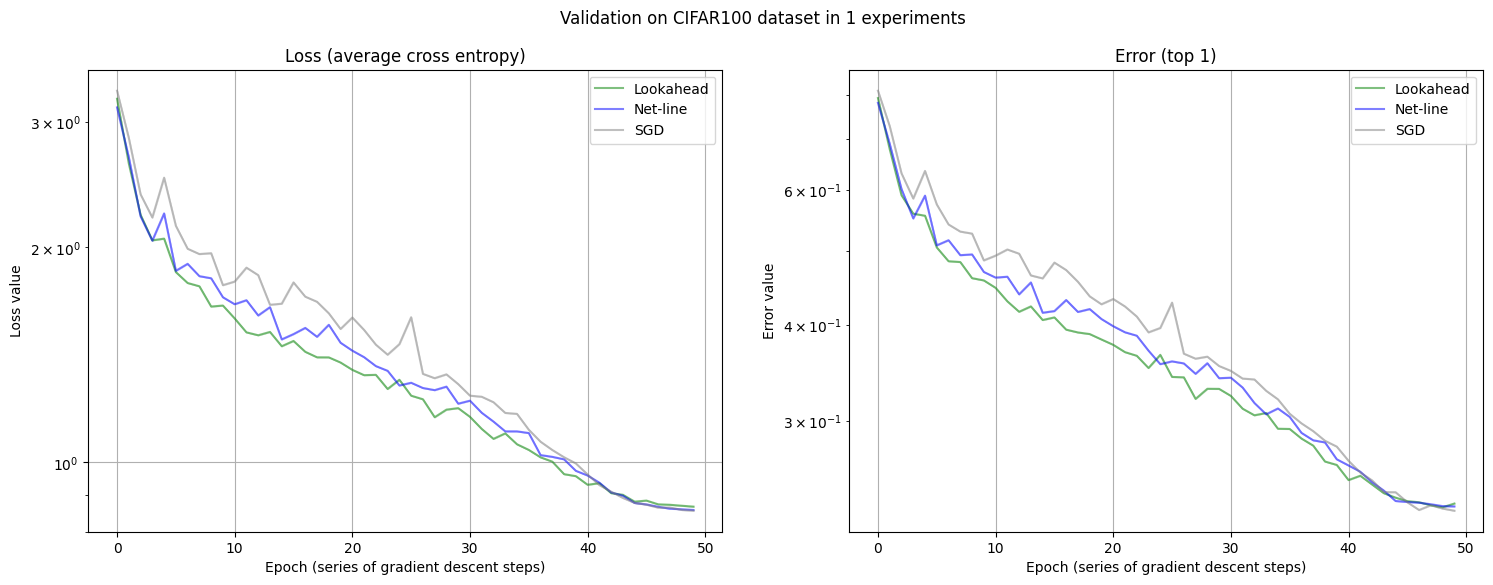

In [11]:
experimental_mean = np.mean(experimental_results, axis=0)
experimental_std = np.std(experimental_results, axis=0)

display.clear_output()
title2="Validation on CIFAR100 dataset in {} experiments".format(EXPERIMENTS)
experiments_comparison(experimental_mean[0:epoch+1], experimental_std[0:epoch+1], 0, 100, title=title2)


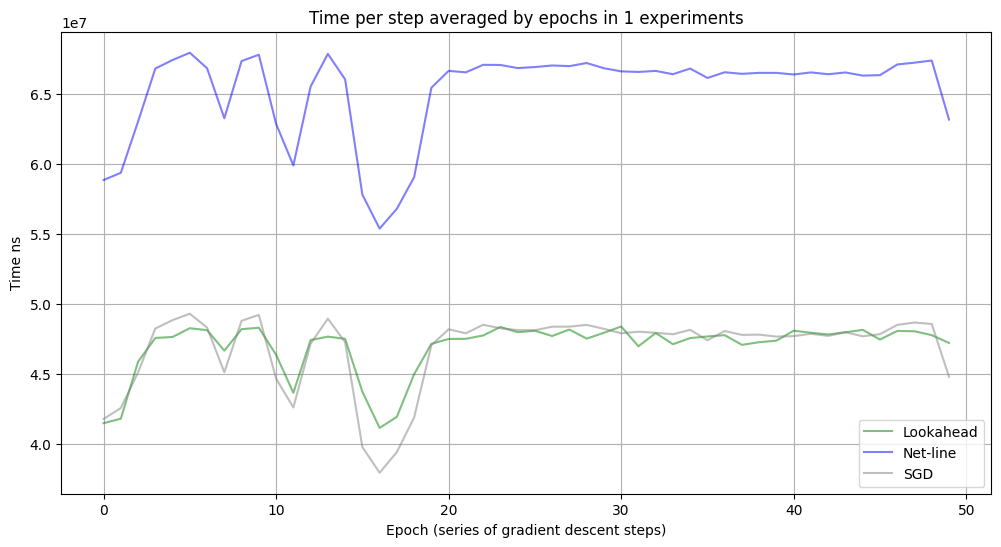

In [12]:
title2="Time per step averaged by epochs in {} experiments".format(EXPERIMENTS)
timing_comparison(experimental_mean[0:epoch+1], 0, 100, title=title2)

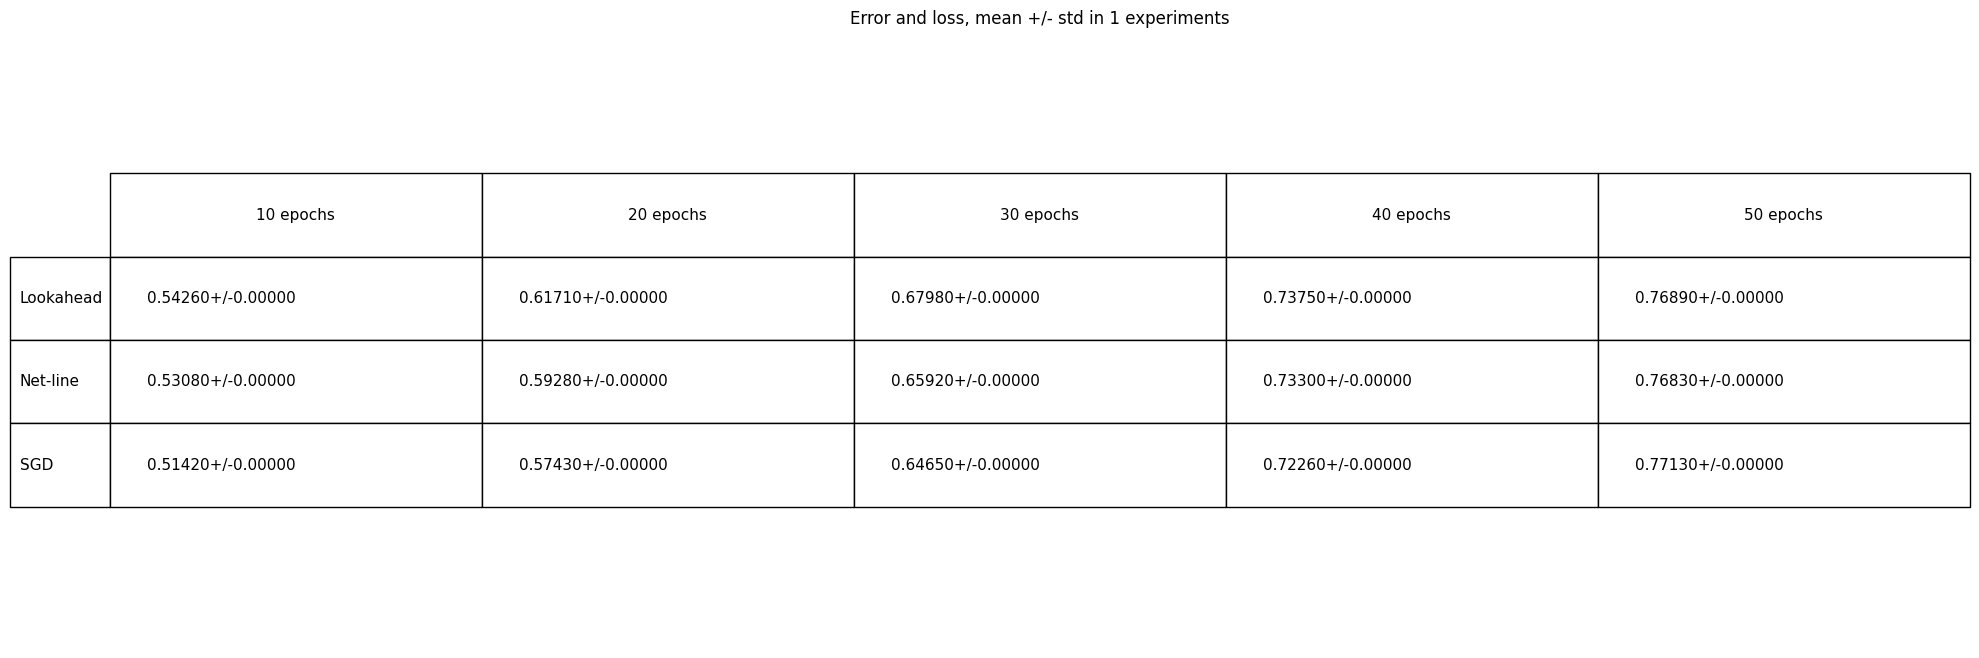

In [13]:
#experimental_results[2, 0:100, 1, 0]
title3 = "Error and loss, mean +/- std in {} experiments".format(EXPERIMENTS)
accuracy_comparison(experimental_results, 0, EPOCHS_PER_EXPERIMENT, title=title3)